# CPPI 2021


# Simulación CPPI Colcap 

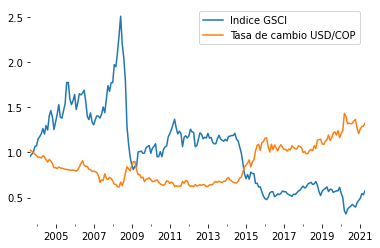

In [ ]:
import pandas as pd
import numpy as np
import Optiport as op
import matplotlib.pyplot as plt #Otro graficador
%matplotlib inline

#%%DICCIONARIO DE FUENTES
import datetime as dt
#Diccionario de fuentes de MatplotLib
fontTitles = {'family': 'Arial',
        'color':  'Orange',
        'weight': 'normal',
        'size': 22,
        }
fontAxis={'family': 'Arial',
        'color':  'darkblue',
        'weight': 'normal',
        'size': 16,
        }
import matplotlib.dates as mdates
import matplotlib.cbook as cbook
years = mdates.YearLocator()   # every year
months = mdates.MonthLocator()  # every month
years_fmt = mdates.DateFormatter('%Y')
month_fmt=mdates.DateFormatter('%M')
day_fmt=mdates.DateFormatter('%D')

#Interactividad
import ipywidgets as widgets
from ipywidgets import interact

#%% MERCADOS
assets={} #Diccionario que contiene los activos admisibles por portafolio


tickers=['COLCAP Index','MXWD Index','SPGSCITR Index','COFX Index','CORRRMIN Index']

nombres=['Indice Colcap','Indice MSCI','Indice GSCI','Tasa de cambio USD/COP','Tasa Banrep']

freq='MONTHLY' # Opciones: 'DAILY', 'MONTHLY' 'WEEKLY','YEARLY'
campo='PX_LAST' # Opciones : ['PX_OPEN','PX_HIGH','PX_LOW','PX_LAST','ADJUSTED_PREV_LAST_PRICE']
inicio='2006-08-01'
fin= '2020-11-30' # En Blanco para que traiga hasta el día más reciente
#Importa los datos

activos=dict(zip(tickers,nombres))

# Aquí lo que importa es la 30 días
# Bloomberg si hay Terminal + blpapi; si no, lee la exportación guardada en SerieCPPI.xlsx
precios=op.precios(tickers,freq,['PX_LAST'],inicio)
rotulos=precios.columns.to_list()
for i in range(len(rotulos)):
    rotulos[i]=rotulos[i][0]
    rotulos[i]=activos[rotulos[i]]
precios.columns=rotulos
#precios.dropna(inplace=True)
precios = precios.reindex(sorted(precios.columns), axis=1)
precios['GSCI en COP']=precios['Indice GSCI']*precios["Tasa de cambio USD/COP"]
precios['MSCI en COP']=precios['Indice MSCI']*precios["Tasa de cambio USD/COP"]
precios['Tasa Banrep']=np.cumprod((precios['Tasa Banrep']+1)**(1/365))
#Calcula retornos aritméticos
retornos=precios.pct_change()
#Limpia los no disponibles
retornos=retornos.dropna()
#Toma las dimensiones de la matriz en términos de columnas.
numAssets=retornos.shape[1]    
#Curvas de patrimonio
cumret=np.cumprod(retornos.drop('Tasa Banrep',axis=1)+1)
cumret[['Indice GSCI','Tasa de cambio USD/COP']]['2003':'2021'].plot()
plt.box(on=None)
plt.savefig('COPvsGSCI')
plt.show()

### Indicamos que los activos riesgosos están dados por las acciones y Commodities

In [ ]:
risky_r=retornos

### Cálculo del Maximum Drawdown:

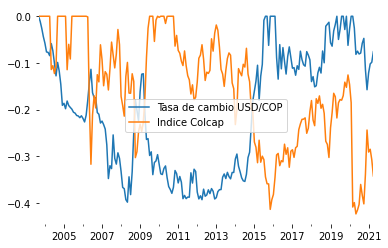

In [ ]:
max_previo=cumret.cummax()
drawdown=(cumret-max_previo)/max_previo
drawdown[['Tasa de cambio USD/COP','Indice Colcap']].plot()
plt.box(on=None)
plt.savefig('Drawdown')
plt.show()

In [ ]:
drawdown.min()

Indice Colcap            -0.423797
Indice GSCI              -0.872176
Indice MSCI              -0.562309
Tasa de cambio USD/COP   -0.398623
GSCI en COP              -0.734355
MSCI en COP              -0.438767
dtype: float64

### Backtesting CPPI Colcap

ind_return=retornos[['Indice Colcap','MSCI en COP','GSCI en COP']]
#Activo riesgoso
risky_r=ind_return.dropna()
#Activo libre de riesgo
risky_r.index.to_period('M')
risky_r.tail()

In [ ]:
safe_r=precios['Tasa Banrep'].pct_change().dropna()

In [ ]:
account_history=pd.DataFrame().reindex_like(risky_r)

Inicializa Variables

In [ ]:
safe_r[:]=0.04/12 # Tasa de rendimiento libre de riesgo al vencimiento (5 años)... TES Agosto 2026 5.94. Seamos conservadores
start=1000
floor=0.95

## El algoritmo implica 3 procesos principales:
1. Cálculo del Colchón (Asset Value menos Piso)
2. Compute una asignación a los activos riesgoso y seguro-->m*risk_budget
3. Recompute el Asset Value basado en los retornos

### Ciclo Backtesting
Importamos de Bloomberg los precios de 3 activos riesgosos desde 2010. Aplicamos el algoritmo de CPPI y evaluamos los resultados, que se almacenan en la variables BTR

In [ ]:
dates=risky_r.index
n_steps=len(dates)
account_value=start
floor_value=start*floor
m=3
account_history=pd.DataFrame().reindex_like(risky_r)
cushion_history=pd.DataFrame().reindex_like(risky_r)
risky_w_history=pd.DataFrame().reindex_like(risky_r)
transaction_cost_history=pd.DataFrame().reindex_like(risky_r)
risky_alloc=0
for step in range(n_steps):
    cushion=(account_value-floor_value)/account_value
    risky_w=m*cushion
    risky_w=np.minimum(risky_w,1)
    risky_w=np.maximum(risky_w,0)
    safe_w=1-risky_w
    risky_prev_w=risky_alloc
    risky_alloc=account_value*risky_w
    safe_alloc=account_value*safe_w
    transaction_cost=abs((risky_alloc-risky_prev_w))*(0.075/100)
    #Descuenta la comisión
    fees=account_value*((1+0.02)**(1/365)-1)
    ##Actualiza el valor de la cuenta
    account_value=risky_alloc*(1+risky_r.iloc[step])+safe_alloc*(1+safe_r.iloc[step])-transaction_cost-fees
    # Guarda los valores para visualizarlos después
    cushion_history.iloc[step]=cushion
    risky_w_history.iloc[step]=risky_w
    account_history.iloc[step]=account_value
    transaction_cost_history.iloc[step]=transaction_cost
    
    

<AxesSubplot:>

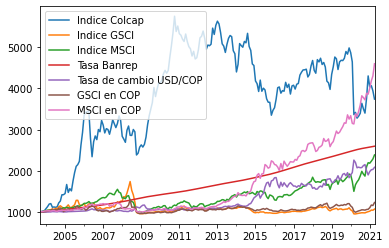

In [ ]:
account_history.plot()

### Esl backtest muestra lo que habría sido el comportamiento de la estrategia.

Text(0.5, 1.0, 'Exposición Directa GSCI en COP (Punteada) vs CPPI(continua)')

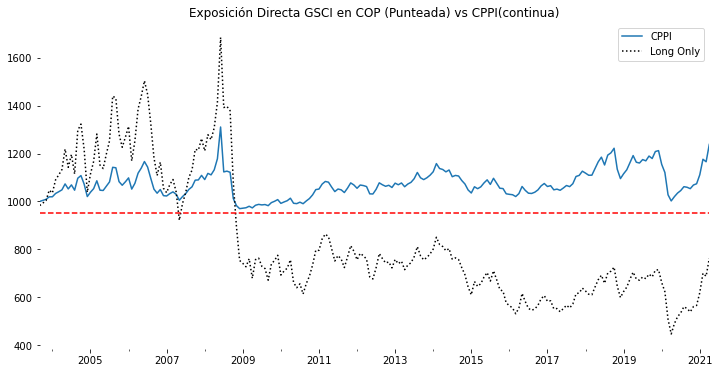

In [ ]:
ax=account_history['GSCI en COP'].plot(figsize=(12,6),legend=True)
(start*(1+risky_r['GSCI en COP']).cumprod()).plot(ax=ax,style='k:',legend='True')
ax.axhline(y=floor_value,color='r',linestyle='--')
plt.legend(['CPPI','Long Only'])
plt.box(on=None)
plt.title('Exposición Directa GSCI en COP (Punteada) vs CPPI(continua)')


### Ponderaciones históricas del portafolio para el  activo 

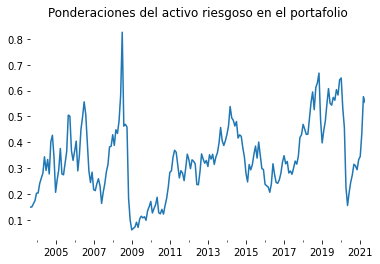

In [ ]:
risky_w_history['GSCI en COP'].plot()
plt.title('Ponderaciones del activo riesgoso en el portafolio')
plt.box(on=None)
plt.show()

<AxesSubplot:>

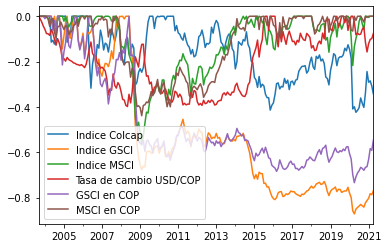

In [ ]:
drawdown=(cumret-max_previo)/max_previo
drawdown.plot()

In [ ]:
#Implementa el Backtesting sobre los retornos importados
btr=op.corre_cppi(risky_r)
btr['CPPI_NAV'].head()

,Indice Colcap,Indice GSCI,Indice MSCI,Tasa Banrep,Tasa de cambio USD/COP,GSCI en COP,MSCI en COP
2003-09-30,1004.928854,975.713038,1003.092066,1003.695557,1015.139934,990.026848,1018.086850
2003-10-31,1040.145518,987.954808,1039.968702,1007.884763,1008.701323,996.856811,1050.014429
2003-11-28,1067.768307,1003.063269,1050.234385,1012.131763,999.867788,1003.482906,1049.185500
2003-12-31,1111.819410,1041.729448,1097.419090,1016.438350,989.529354,1030.362560,1081.650566
2004-01-30,1278.609798,1045.011471,1112.115447,1020.805359,981.785727,1023.298868,1082.947663


#  Restricción al Drawdown

Incluír una restricción de retroceso máximo reduce sustancialmente la rentabilidad objetivo , pero puede ser una alternativa a considerar mas adelante si el producto observa valorizacción durante el primer año o año y medio 

In [ ]:
btr=op.corre_cppi(risky_r["2003":],drawdown=0.05)

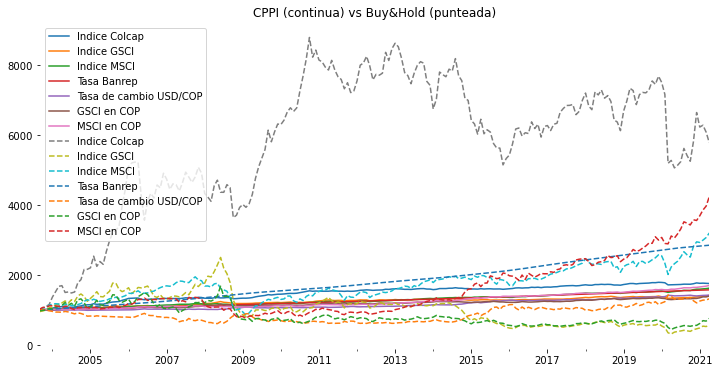

In [ ]:
ax=btr["CPPI_NAV"].plot(figsize=(12,6))
btr["buy&hold"].plot(ax=ax,style='--')
plt.title('CPPI (continua) vs Buy&Hold (punteada)')
plt.box(on=None)
plt.show()

# Simulación Montecarlo 

Implementamos simulación de montecarlo para validar las violación de las restricciones

In [ ]:
#Una función para generar precios aleatorios
def gbm(n_years=5,n_scenarios=1000,mu=0.06,sigma=0.15,n_steps=12,s_0=100):
    """Evolución del activo volatil usando Movimiento Browniano Geométrico"""
    dt=1/n_steps
    n_steps=int(n_years*n_steps)
    #Normales aleatorias
    #Contenedor
    rets_plus1=np.random.normal(loc=(1+mu*dt),scale=(sigma*np.sqrt(dt)),size=(n_steps+1,n_scenarios))
    rets_plus1[0]=1
    #Convierte a niveles
    precios=s_0*pd.DataFrame(rets_plus1).cumprod()
    return precios

In [ ]:
#simColcap=gbm(5,n_scenarios=1000,mu=risky_r['Indice Colcap'].mean(),sigma=risky_r['Indice Colcap'].std(),n_steps=12,s_0=precios['Indice Colcap'].iloc[-1])

### Calibración del modelo y análisis de escenarios

Los riesgos principales son un incremento en la volatilidad que genere una caída en el valor del activo riesgoso acompañado de una imposibilidad de rebalancear. 

In [ ]:
mu=risky_r['GSCI en COP']['2003':'2007'].mean() #Retorno promedio esperado 
sigma=risky_r['GSCI en COP'].std() #Desviación estándar del retorno 
MDD=op.drawdown(cumret['GSCI en COP'].dropna()) # Maximum Drawdown
n_steps=12
s_0=precios['GSCI en COP'].iloc[-1]

print('mu=',str(mu*n_steps),' sigma=',str(sigma*np.sqrt(n_steps)), 'MDD=',str(MDD))

mu= 0.08289452606960905  sigma= 0.21954230468107533 MDD=                   Wealth  Previous Peak  Drawdown
2003-09-30  1.983017e+03   1.983017e+03       0.0
2003-10-31  3.953394e+03   3.953394e+03       0.0
2003-11-28  7.921261e+03   7.921261e+03       0.0
2003-12-31  1.621326e+04   1.621326e+04       0.0
2004-01-30  3.299945e+04   3.299945e+04       0.0
...                  ...            ...       ...
2020-12-31  1.547898e+57   1.547898e+57       0.0
2021-01-29  2.507338e+57   2.507338e+57       0.0
2021-02-26  4.263495e+57   4.263495e+57       0.0
2021-03-31  7.197131e+57   7.197131e+57       0.0
2021-04-30  1.269103e+58   1.269103e+58       0.0

[212 rows x 3 columns]


# Calibración para el CPPI

Evaluación de sensibilidades para cada subyacente y parámetro. Se importa IpyWidgets para la aplicación de simulaciones 

In [ ]:
from IPython.display import display

In [ ]:
from IPython.display import display
%load_ext autoreload
%autoreload 2
%matplotlib inline

asset='GSCI en COP'
mu=risky_r[asset].loc['2003':'2007'].mean()
sigma=risky_r[asset].std()
MDD=op.drawdown(cumret[asset].dropna())
n_steps=12
s_0=precios[asset].iloc[-1]

print('mu=',str(mu*12),' sigma=',str(sigma*np.sqrt(12)), 'MDD=',str(MDD))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
mu= 0.08289452606960905  sigma= 0.21954230468107533 MDD=                   Wealth  Previous Peak  Drawdown
2003-09-30  1.983017e+03   1.983017e+03       0.0
2003-10-31  3.953394e+03   3.953394e+03       0.0
2003-11-28  7.921261e+03   7.921261e+03       0.0
2003-12-31  1.621326e+04   1.621326e+04       0.0
2004-01-30  3.299945e+04   3.299945e+04       0.0
...                  ...            ...       ...
2020-12-31  1.547898e+57   1.547898e+57       0.0
2021-01-29  2.507338e+57   2.507338e+57       0.0
2021-02-26  4.263495e+57   4.263495e+57       0.0
2021-03-31  7.197131e+57   7.197131e+57       0.0
2021-04-30  1.269103e+58   1.269103e+58       0.0

[212 rows x 3 columns]


In [ ]:
def show_cppi(inicio=1000,n_years=5,n_scenarios=100,mu=0,sigma=0.15,m=3,piso=0.,rf=0.0175,y_max=1000):
    """Grafica el resultado de la simulación del CPPI"""
    start=inicio
    sim_rets=op.gbm(n_years=n_years,n_scenarios=n_scenarios,mu=mu,sigma=sigma,prices=False,steps_per_year=12)
    risky_r=pd.DataFrame(sim_rets)
    #"Corre el Backtest"
    btr=op.run_cppi(risky_r=pd.DataFrame(risky_r),riskfree_rate=rf,m=m,start=start,floor=piso,drawdown=None)
    wealth=btr['Wealth']
    y_max=wealth.values.max()*y_max/1000
    #Calcula valores terminales
    terminal_wealth=wealth.iloc[-1] 
    #Grafico
    fig,(wealth_ax,hist_ax)=plt.subplots(nrows=1, ncols=2,sharey=True,gridspec_kw={'width_ratios':[3,2]},figsize=(24,9))
    plt.subplots_adjust(wspace=0)
   
    wealth.plot(ax=wealth_ax,legend=False,alpha=0.3,color='blue')
    
    wealth_ax.axhline(y=start,ls=":",color="black")
    wealth_ax.axhline(y=start*piso,ls="--",color='red')
    wealth_ax.set_ylim(top=y_max)
    
    terminal_wealth.plot.hist(ax=hist_ax,bins=50,ec='w',fc='blue',orientation='horizontal')
    tw_mean=terminal_wealth.mean()
    tw_median=terminal_wealth.median()
    failure_mask=np.less(terminal_wealth,inicio*piso)
    n_failures=failure_mask.sum()
    p_fail=n_failures/n_scenarios
    e_shortfall=np.dot(terminal_wealth-inicio*piso,failure_mask)/n_failures if n_failures>0 else 0.0
    
    hist_ax.axhline(y=start,ls=':',color='black',linewidth=4)
    hist_ax.axhline(y=tw_median,ls=':',color='purple',linewidth=4)
    hist_ax.axhline(y=tw_mean,ls=':',color='indianred',linewidth=4)
    hist_ax.annotate(f"Promedio: ${int(tw_mean)}",xy=(.5,.9),xycoords='axes fraction',fontsize=20)
    hist_ax.annotate(f"Mediana: ${int(tw_median)}",xy=(.5,.85),xycoords='axes fraction',fontsize=20)
    if (floor>0.01):
        hist_ax.axhline(y=inicio*piso,ls="--",color='red',linewidth=4)
        hist_ax.annotate(f"Violaciones: {n_failures}({p_fail*100:2.2f}%)\nE(shortfall)=${e_shortfall:2.2f}",xy=(.5,.7),xycoords='axes fraction',fontsize=20)
     


In [ ]:
controles_cppi=widgets.interactive(show_cppi,
                                 n_years=widgets.IntSlider(min=1,max=10,step=1,value=5),
                                 n_scenarios=widgets.IntSlider(min=1,max=1000,step=5,value=100),
                                 mu=(0,0.2,0.01),
                                 sigma=(0,0.5,0.005),
                                 piso=(0.8,2,.05),
                                 m=(1,5,0.5),
                                 rf=(0,0.08,0.01),
                                 y_max=widgets.IntSlider(min=0,max=3000,step=100,value=1000,description="Zoom Eje Y"                                                        
                                 )
                                 )
display(controles_cppi)

interactive(children=(IntSlider(value=1000, description='inicio', max=3000, min=-1000), IntSlider(value=5, des…

In [ ]:
1.097**(1/5)

1.0186883172534826

In [ ]:
1.28**(1/5)

1.0506111217615068